# Employee Attrition Prediction — Group 5_C9

Which employees are likely to leave, and what is linked to leaving?
Data: IBM HR Analytics Employee Attrition (fictional, 1,470 employees, 16% left).
Full context, team and how to run: see the repository
[README](https://github.com/Trumpibeabuchi/techcrush-c9-group5-attrition#readme).

**Hypotheses (written before the analysis):**
H1 overtime · H2 pay · H3 tenure/age · H4 satisfaction · H5 travel · H6 job role ·
H7 gender/education (control)

**Note:** units are not documented, and the data is fictional, so results are
compared in relative terms.

## 1. Setup

Libraries used throughout the notebook, and a `figures/` folder for the charts used in the report and slides.

In [1]:
# Import libraries for data manipulation

import pandas as pd
import numpy as np

# Import libraries for data visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries for data preprocessing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import machine learning algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Import statistical tests used in the EDA

from scipy.stats import chi2_contingency, mannwhitneyu

# Import cross-validation tools

from sklearn.model_selection import cross_validate, StratifiedKFold

# Import tools for saving models

import joblib

# Other libraries

import os
import warnings

warnings.filterwarnings("ignore")

# Set visualization style

sns.set_theme(style="whitegrid")

# Display all columns

pd.set_option("display.max_columns", None)

# Folder for exported charts (used in the report and slides)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

print("All libraries imported successfully.")

All libraries imported successfully.


## 2. Data Loading

The CSV is stored in the `data/` folder of this repository and read from there.

In [2]:
# Load the dataset directly from the team GitHub repository,
# so 'Run all' works without a manual upload.

DATA_URL = (
    "https://raw.githubusercontent.com/Trumpibeabuchi/techcrush-c9-group5-attrition/"
    "main/data/WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

df = pd.read_csv(DATA_URL)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
# Dataset dimensions

n_rows, n_cols = df.shape

print(f"The dataset has {n_rows:,} rows (employees) and {n_cols} columns.")

The dataset has 1,470 rows (employees) and 35 columns.


**Finding:** each row is one employee (1,470 in total), described by 35 columns.
The target is `Attrition` (Yes = the employee left, No = stayed).

## 3. Data Quality Assessment

Before exploring patterns, we check that the data can be trusted: are values missing or
duplicated, do the numbers and categories make sense, and does every column carry useful
information? The section ends with the cleaning decisions.

### 3.1 Data types and missing values

`df.info()` shows each column's type and how many values are filled in.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [5]:
# Total number of missing values across the whole dataset

print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


**Finding:** no missing values: every column has 1,470 non-null entries.
Types are as expected: 26 numeric columns and 9 text (categorical) columns.

### 3.2 Duplicate records

Every row has a unique `EmployeeNumber`, so comparing whole rows could never find a duplicate.
We therefore check for duplicates **ignoring the ID**: two rows identical in everything else
would be the same employee entered twice.

In [6]:
# Is the employee ID unique?

print("EmployeeNumber is unique:", df["EmployeeNumber"].is_unique)

# Duplicates when the ID is ignored

duplicates = df.drop(columns="EmployeeNumber").duplicated().sum()

print("Duplicate records (ignoring the ID):", duplicates)

EmployeeNumber is unique: True
Duplicate records (ignoring the ID): 0


**Finding:** no duplicate employees, so no rows need to be removed.

### 3.3 Value ranges and categories

We check that numbers fall in sensible ranges and that categories contain no typos or
placeholder values such as "?" or "Unknown" (missing values in disguise, which
`isnull()` would not catch).

In [7]:
# Summary of numerical columns

df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [8]:
# Summary of categorical columns

df.describe(include="object")

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


In [9]:
# List the categories of each text column, to spot typos or placeholders

for column in df.select_dtypes(include="object").columns:
    print(f"{column}: {sorted(df[column].unique())}")

Attrition: ['No', 'Yes']
BusinessTravel: ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
Department: ['Human Resources', 'Research & Development', 'Sales']
EducationField: ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']
Gender: ['Female', 'Male']
JobRole: ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
MaritalStatus: ['Divorced', 'Married', 'Single']
Over18: ['Y']
OverTime: ['No', 'Yes']


In [10]:
# Logical consistency: years at the company cannot exceed total working years,
# and years in the current role cannot exceed years at the company

print("YearsAtCompany > TotalWorkingYears:",
      (df["YearsAtCompany"] > df["TotalWorkingYears"]).sum())

print("YearsInCurrentRole > YearsAtCompany:",
      (df["YearsInCurrentRole"] > df["YearsAtCompany"]).sum())

YearsAtCompany > TotalWorkingYears: 0
YearsInCurrentRole > YearsAtCompany: 0


**Finding:**
1. All values are plausible.
2. Age runs from 18 to 60, years at the company
from 0 to 40, and the satisfaction scores from 1 to 4.
3. Every category is a clean label,
with no typos or placeholder values, and the year columns are consistent with each other.

**NOTE:** Units are not documented: income has no currency and distance from home has no unit.
Because the data is also fictional, results are compared in relative terms
(for example "leavers earn X% less"), never in a specified currency.

### 3.4 Constant and identifier columns

A column with the same value for every employee cannot help to tell leavers from stayers.

In [11]:
# Columns with only one unique value

constant_columns = [
    column for column in df.columns
    if df[column].nunique() == 1
]

print("Constant columns:", constant_columns)

Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


**Finding:** `EmployeeCount` (always 1), `Over18` (always "Y") and `StandardHours`
(always 80) are constant.

### 3.5 Which column measures pay?

The dataset has four pay-like columns: `MonthlyIncome`, `MonthlyRate`, `DailyRate` and
`HourlyRate`. If they all measured pay, they would rise and fall together, and they
would rise with seniority. We compare them with each other and with two seniority
columns, `JobLevel` and `TotalWorkingYears`.

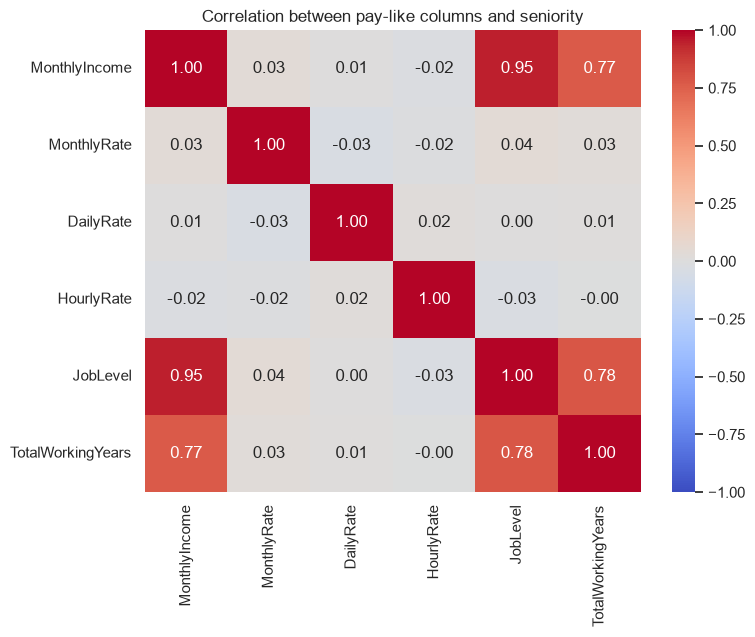

In [12]:
pay_columns = [
    "MonthlyIncome", "MonthlyRate", "DailyRate", "HourlyRate",
    "JobLevel", "TotalWorkingYears"
]

pay_corr = df[pay_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    pay_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation between pay-like columns and seniority")

plt.savefig(
    f"{FIG_DIR}/pay_columns_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Finding:** `MonthlyIncome` behaves like real pay. It rises strongly with job level
(correlation 0.95) and total working years (0.77). The three "Rate" columns are not
related to income, to each other, or to seniority (all correlations between −0.03 and
0.04), so their meaning is unclear. **EDA will therefore use `MonthlyIncome`
only.** The Rate columns are kept in the data; whether they are used in the models is a
modelling decision.

### 3.6 Summary and cleaning decisions

| Check | Result | Action |
|---|---|---|
| Missing values | None | None |
| Duplicates | None (checked ignoring the ID) | None |
| Value ranges and categories | Plausible and clean; units not documented | Compare results in relative terms |
| Constant columns | `EmployeeCount`, `Over18`, `StandardHours` | Drop |
| Identifier | `EmployeeNumber` | Drop |
| Pay columns | Only `MonthlyIncome` behaves like pay | Use `MonthlyIncome` for EDA; flag Rate columns for modelling |

The cleaned data is stored as `df_clean` and used in the rest of the notebook.

In [13]:
# Drop the constant columns and the identifier

columns_to_drop = constant_columns + ["EmployeeNumber"]

df_clean = df.drop(columns=columns_to_drop)

print("Dropped:", columns_to_drop)
print(f"Cleaned data: {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns.")

Dropped: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Cleaned data: 1,470 rows and 31 columns.


## 4. Exploratory Data Analysis

Which factors are linked to employees leaving? The analysis is organised around the
hypotheses written **before** looking at the data. Each subsection tests one hypothesis
and ends with a finding. Charts compare leavers with stayers, using **attrition rates**
(the % of a group who left) rather than counts, because the groups differ in size.
These are associations, not causes.

| Section | Question |
|---|---|
| 4.1 Attrition distribution | How many employees left? (baseline for everything else) |
| 4.2 H1 Overtime | Do employees who work overtime leave more? |
| 4.3 H2 Pay | Is lower monthly income linked to leaving, even within the same job level? |
| 4.4 H3 Tenure and age | Do newer and younger employees leave more? |
| 4.5 H4 Satisfaction | Are low job/environment satisfaction and poor work-life balance linked to leaving? |
| 4.6 H5 Business travel | Do frequent travellers leave more? |
| 4.7 H6 Job role | Does attrition differ strongly by job role (and department)? |
| 4.8 H7 Gender and education (control) | Do these make little difference, as expected? |
| 4.9 Correlation overview | Which numeric variables are most linked to leaving? |
| 4.10 Hypothesis scorecard | Summary: supported, partly supported or not supported |

### 4.1 Attrition distribution

How many employees left? This overall rate is the baseline that every group is compared with.

In [14]:
# Number and percentage of employees who left (Yes) and stayed (No)

attrition_summary = pd.DataFrame({
    "Employees": df_clean["Attrition"].value_counts(),
    "Percentage (%)": (df_clean["Attrition"].value_counts(normalize=True) * 100).round(1)
})

attrition_summary

,Employees,Percentage (%)
Attrition,,
No,1233,83.9
Yes,237,16.1


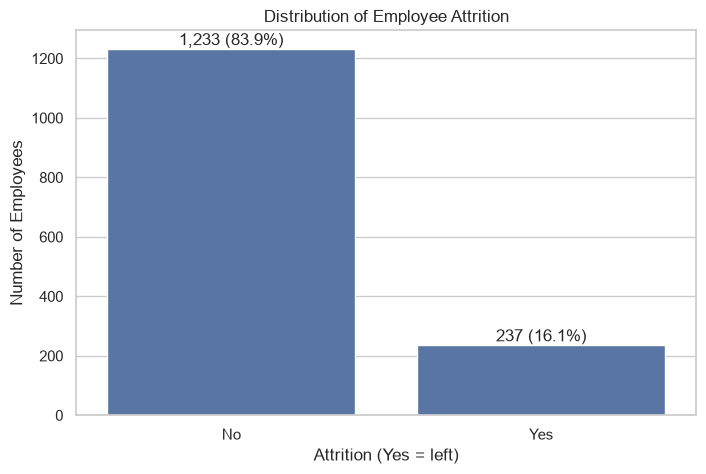

In [15]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x="Attrition",
    order=["No", "Yes"]
)

# Label each bar with its count and percentage

total = len(df_clean)

for bar in ax.patches:
    count = int(bar.get_height())
    ax.annotate(
        f"{count:,} ({count / total:.1%})",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom"
    )

plt.title("Distribution of Employee Attrition")

plt.xlabel("Attrition (Yes = left)")

plt.ylabel("Number of Employees")

plt.savefig(
    f"{FIG_DIR}/attrition_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Finding:** 237 of 1,470 employees (16.1%) left, about 1 in 6. This 16.1% is the
baseline: a group with a clearly higher rate is at higher risk. The classes are
imbalanced: a model that predicts "stays" for everyone would be 84% accurate yet find
no leavers, so the models are judged on precision, recall and F1, not accuracy alone.
(The 16.1% is the share of leavers in this snapshot, not an annual turnover rate.)

### How each hypothesis is tested

For every hypothesis we:

1. Compare the **attrition rate** (% of the group who left) with the overall 16.1%.
2. Check with a **statistical test** whether the difference could just be chance:
   the *chi-square test* for categories (e.g. overtime Yes/No) and the *Mann-Whitney U
   test* for numbers such as income (it compares leavers with stayers without
   assuming the values are normally distributed). Rule: **p < 0.05** means the
   difference is statistically significant.
3. State whether the hypothesis is supported.

The helper functions below do steps 1 and 2 the same way for every hypothesis.

In [16]:
# Copy of the cleaned data for the EDA, so helper columns added here
# (e.g. age bands) do not end up in the modelling data

eda_df = df_clean.copy()

# Overall attrition rate: the reference line on every chart

overall_rate = (eda_df["Attrition"] == "Yes").mean() * 100

print(f"Overall attrition rate: {overall_rate:.1f}%")


def attrition_rate(column, order=None):
    """Employees, leavers and attrition rate (%) for each group of a column."""
    table = eda_df.groupby(column, observed=True)["Attrition"].agg(
        Employees="size",
        Left=lambda s: (s == "Yes").sum()
    )
    table["Attrition Rate (%)"] = (table["Left"] / table["Employees"] * 100).round(1)
    if order is not None:
        table = table.reindex(order)
    return table


def plot_attrition_rate(column, order=None, title=None, filename=None, horizontal=False):
    """Bar chart of the attrition rate per group, with the overall rate as a dashed line."""
    table = attrition_rate(column, order)
    labels = table.index.astype(str)
    rates = table["Attrition Rate (%)"].values

    plt.figure(figsize=(9, 6) if horizontal else (9, 5))

    if horizontal:
        ax = sns.barplot(x=rates, y=labels, color="steelblue")
        ax.axvline(overall_rate, ls="--", color="grey", label=f"Overall rate {overall_rate:.1f}%")
        ax.set_xlabel("Attrition rate (%)")
        ax.set_ylabel("")
        ax.set_xlim(0, rates.max() * 1.15)
        for i, v in enumerate(rates):
            ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
    else:
        ax = sns.barplot(x=labels, y=rates, color="steelblue")
        ax.axhline(overall_rate, ls="--", color="grey", label=f"Overall rate {overall_rate:.1f}%")
        ax.set_ylabel("Attrition rate (%)")
        ax.set_xlabel(column)
        ax.set_ylim(0, rates.max() * 1.15)
        for i, v in enumerate(rates):
            ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")

    ax.set_title(title or f"Attrition rate by {column}")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  # outside the plot, so it never covers a bar label
    if filename:
        plt.savefig(f"{FIG_DIR}/{filename}", dpi=300, bbox_inches="tight")
    plt.show()
    return table


def chi_square_test(column):
    """Chi-square test: is attrition independent of this categorical column?"""
    contingency = pd.crosstab(eda_df[column], eda_df["Attrition"])
    chi2, p, dof, expected = chi2_contingency(contingency)
    verdict = "significant" if p < 0.05 else "NOT significant"
    print(f"Chi-square test, {column} vs Attrition: chi2 = {chi2:.1f}, p = {p:.2g} -> {verdict} at the 5% level")
    return p


def mann_whitney_test(column):
    """Mann-Whitney U test: do leavers and stayers differ on a numeric column?"""
    left = eda_df.loc[eda_df["Attrition"] == "Yes", column]
    stayed = eda_df.loc[eda_df["Attrition"] == "No", column]
    stat, p = mannwhitneyu(left, stayed, alternative="two-sided")
    verdict = "significant" if p < 0.05 else "NOT significant"
    print(f"Median {column}: left = {left.median():,.0f}, stayed = {stayed.median():,.0f}")
    print(f"Mann-Whitney U test: p = {p:.2g} -> {verdict} at the 5% level")
    return p

Overall attrition rate: 16.1%


### 4.2 H1: Overtime

**Hypothesis:** employees who work overtime leave more.

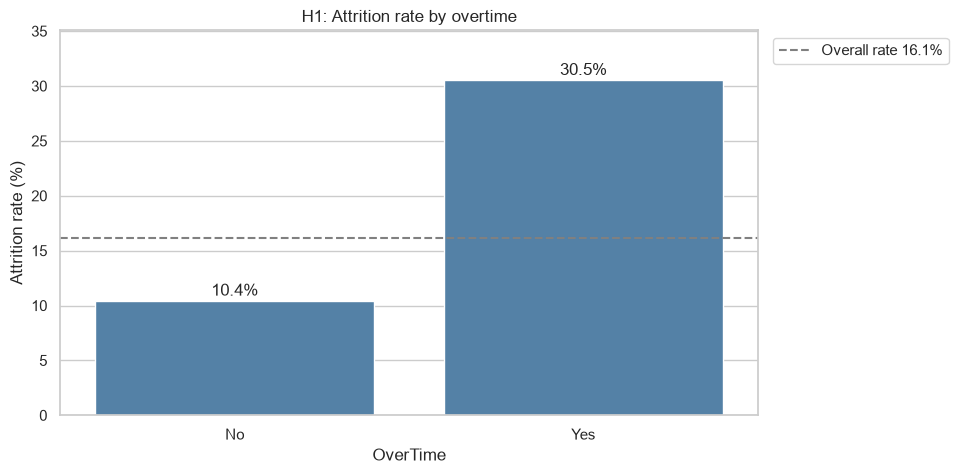

,Employees,Left,Attrition Rate (%)
OverTime,,,
No,1054,110,10.4
Yes,416,127,30.5


In [17]:
plot_attrition_rate(
    "OverTime",
    order=["No", "Yes"],
    title="H1: Attrition rate by overtime",
    filename="h1_overtime.png"
)

In [18]:
chi_square_test("OverTime");

Chi-square test, OverTime vs Attrition: chi2 = 87.6, p = 8.2e-21 -> significant at the 5% level


**Finding (H1): supported.** Employees who work overtime are far more likely to leave:
30.5% of them left, against 10.4% of those who don't, about **3 times the rate**
(statistically significant, p < 0.001). Overtime workers are only 28% of staff
(416 of 1,470) but make up 54% of all leavers (127 of 237).

**What it means for HR:** regular overtime is a clear early-warning sign. HR should
track who works overtime regularly and manage workload and rest in those teams.
Because this is an association, not proof of cause, overtime may also point to other
problems in those teams, such as understaffing.

### 4.3 H2: Pay

**Hypothesis:** lower monthly income is linked to more leaving.

Income is skewed (a few high earners pull the average up), so leavers and stayers are
compared on the **median** and with the Mann-Whitney test.

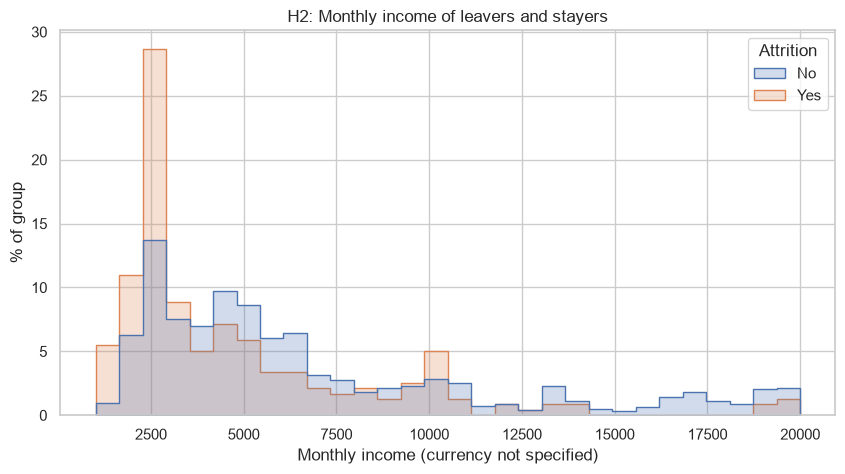

Median MonthlyIncome: left = 3,202, stayed = 5,204
Mann-Whitney U test: p = 3e-14 -> significant at the 5% level


In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="MonthlyIncome",
    hue="Attrition",
    hue_order=["No", "Yes"],
    bins=30,
    stat="percent",
    common_norm=False,
    element="step"
)

plt.title("H2: Monthly income of leavers and stayers")

plt.xlabel("Monthly income (currency not specified)")

plt.ylabel("% of group")

plt.savefig(
    f"{FIG_DIR}/h2_income_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

mann_whitney_test("MonthlyIncome");

#### Is it really pay, or just seniority?

Section 3.5 showed that income rises almost in step with job level (correlation 0.95).
Leavers may earn less simply because they are more junior. To separate the two, we
first look at attrition by job level, then compare leavers' and stayers' pay
**within the same job level**. If leavers still earn clearly less inside each level,
pay matters in its own right; if the gap disappears, the effect is mostly about being
junior.

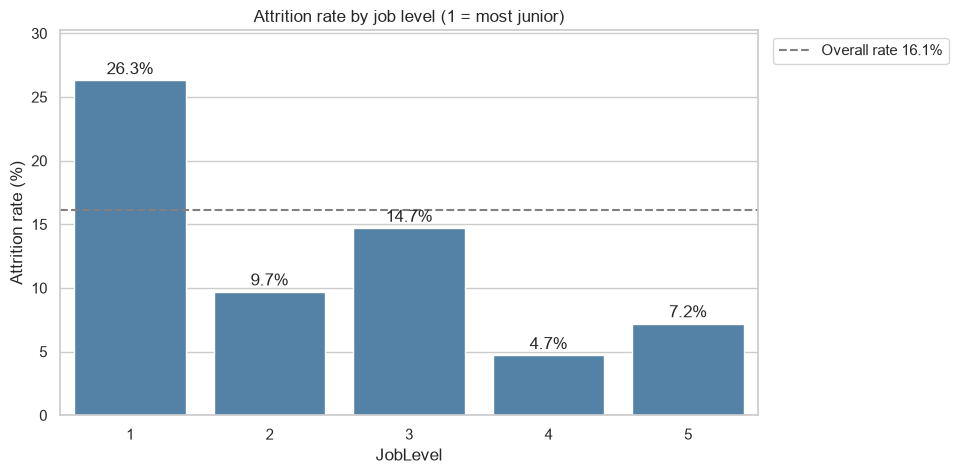

,Employees,Left,Attrition Rate (%)
JobLevel,,,
1,543,143,26.3
2,534,52,9.7
3,218,32,14.7
4,106,5,4.7
5,69,5,7.2


In [20]:
plot_attrition_rate(
    "JobLevel",
    title="Attrition rate by job level (1 = most junior)",
    filename="h2_attrition_by_joblevel.png"
)

In [21]:
# Median income of leavers vs stayers within each job level,
# with the gap in % (relative terms, because the currency is not documented)

income_by_level = (
    eda_df.groupby(["JobLevel", "Attrition"])["MonthlyIncome"]
    .median()
    .unstack()
    .rename(columns={"No": "Median income: stayed", "Yes": "Median income: left"})
)

income_by_level["Leavers vs stayers (%)"] = (
    (income_by_level["Median income: left"] / income_by_level["Median income: stayed"] - 1) * 100
).round(1)

income_by_level["Leavers (n)"] = eda_df[eda_df["Attrition"] == "Yes"].groupby("JobLevel").size()

income_by_level

Attrition,Median income: stayed,Median income: left,Leavers vs stayers (%),Leavers (n)
JobLevel,,,,
1,2719.0,2437.0,-10.4,143
2,5334.5,5346.0,0.2,52
3,9982.5,9887.0,-1.0,32
4,16307.0,13194.0,-19.1,5
5,19199.5,19545.0,1.8,5


In [22]:
# Is the pay gap within job level 1 (the level with most leavers) more than chance?

level_1 = eda_df[eda_df["JobLevel"] == 1]

left = level_1.loc[level_1["Attrition"] == "Yes", "MonthlyIncome"]
stayed = level_1.loc[level_1["Attrition"] == "No", "MonthlyIncome"]

stat, p = mannwhitneyu(left, stayed, alternative="two-sided")

print(f"Job level 1: median income left = {left.median():,.0f}, stayed = {stayed.median():,.0f}")
print(f"Mann-Whitney U test: p = {p:.2g} -> {'significant' if p < 0.05 else 'NOT significant'} at the 5% level")

Job level 1: median income left = 2,437, stayed = 2,719
Mann-Whitney U test: p = 0.00041 -> significant at the 5% level


**Finding (H2): partly supported.** Overall, leavers earn clearly less: their median
monthly income is **38% lower** than stayers' (statistically significant, p < 0.001).
But most of this gap reflects **seniority, not pay itself**: job level 1 has by far the
highest attrition (26.3%, against 4.7–14.7% at levels 2–5) and accounts for 60% of all
leavers, and level 1 is also the lowest-paid. When leavers and stayers are compared
**within the same job level**, the gap almost disappears at levels 2, 3 and 5 (within
±2%). The exception is **level 1**, where leavers earn about **10% less** than stayers
at the same level (significant, p < 0.001). (The −19% at level 4 rests on only 5
leavers and is not reliable.)

**What it means for HR:** across-the-board pay rises are not supported by this data.
The target is the entry level: review pay for level-1 staff, especially the
lowest-paid within that level, and the speed of progression out of level 1.

### 4.4 H3: Tenure and age

**Hypothesis:** employees in their first 2 years, and younger staff, leave more.

Years at the company and age are grouped into bands so that rates can be compared.
The bands are added to `eda_df` only; the modelling uses the original columns.

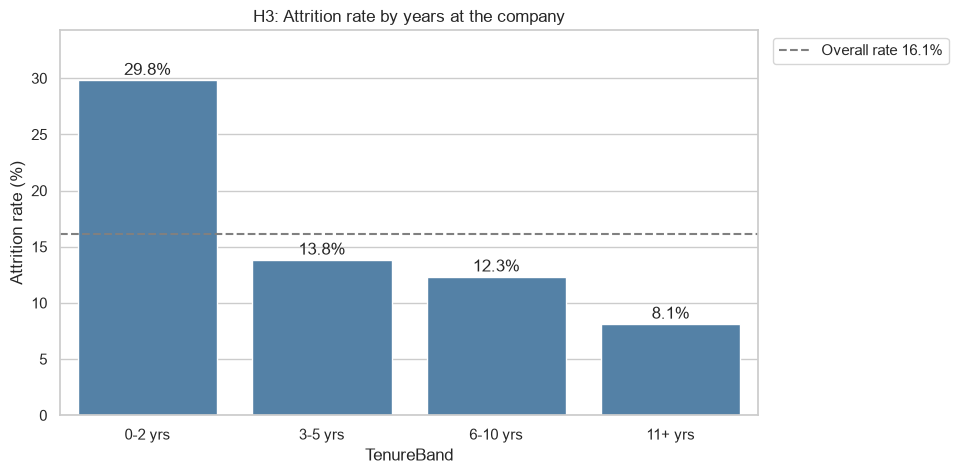

,Employees,Left,Attrition Rate (%)
TenureBand,,,
0-2 yrs,342,102,29.8
3-5 yrs,434,60,13.8
6-10 yrs,448,55,12.3
11+ yrs,246,20,8.1


In [23]:
eda_df["TenureBand"] = pd.cut(
    eda_df["YearsAtCompany"],
    bins=[-1, 2, 5, 10, 40],
    labels=["0-2 yrs", "3-5 yrs", "6-10 yrs", "11+ yrs"]
)

plot_attrition_rate(
    "TenureBand",
    title="H3: Attrition rate by years at the company",
    filename="h3_tenure.png"
)

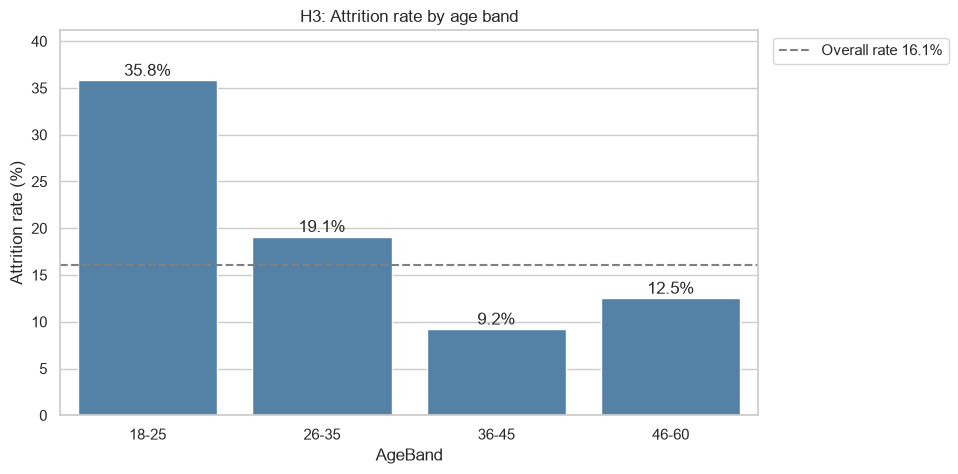

,Employees,Left,Attrition Rate (%)
AgeBand,,,
18-25,123,44,35.8
26-35,606,116,19.1
36-45,468,43,9.2
46-60,273,34,12.5


In [24]:
eda_df["AgeBand"] = pd.cut(
    eda_df["Age"],
    bins=[17, 25, 35, 45, 60],
    labels=["18-25", "26-35", "36-45", "46-60"]
)

plot_attrition_rate(
    "AgeBand",
    title="H3: Attrition rate by age band",
    filename="h3_age.png"
)

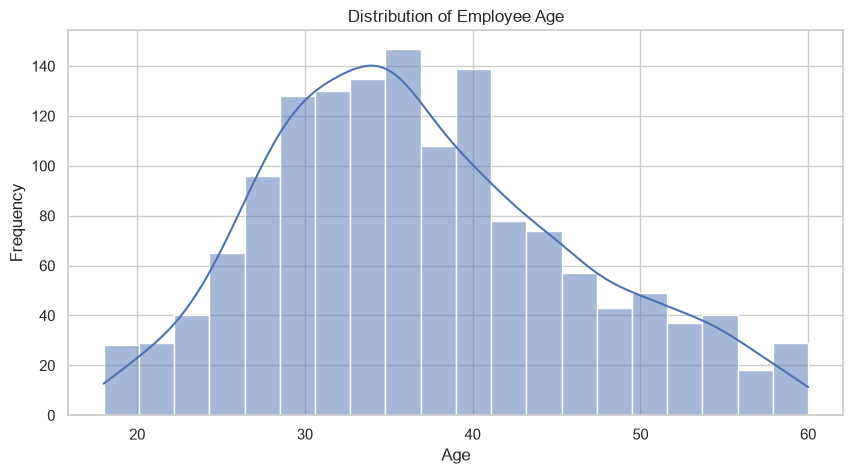

In [25]:
# Age profile of the whole workforce (context)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Distribution of Employee Age")

plt.xlabel("Age")

plt.ylabel("Frequency")

plt.savefig(
    f"{FIG_DIR}/age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

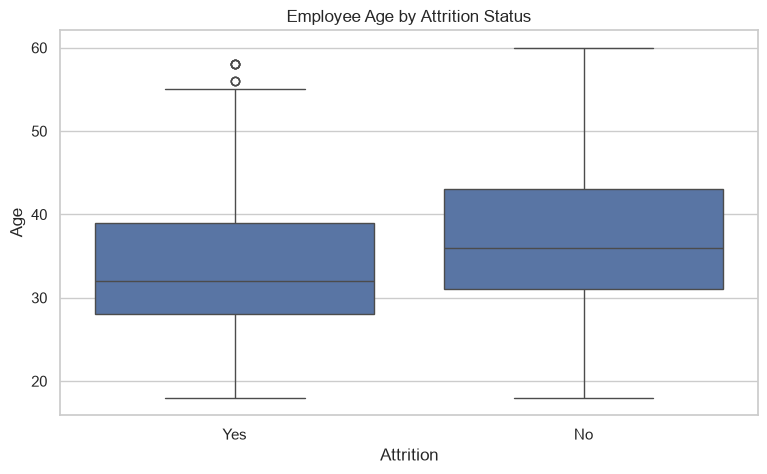

In [26]:
# Age of leavers vs stayers

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=eda_df,
    x="Attrition",
    y="Age"
)

plt.title("Employee Age by Attrition Status")

plt.xlabel("Attrition")

plt.ylabel("Age")

plt.savefig(
    f"{FIG_DIR}/age_by_attrition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
mann_whitney_test("YearsAtCompany")
mann_whitney_test("Age");

Median YearsAtCompany: left = 3, stayed = 6
Mann-Whitney U test: p = 2.9e-13 -> significant at the 5% level
Median Age: left = 32, stayed = 36
Mann-Whitney U test: p = 5.3e-11 -> significant at the 5% level


**Finding (H3): supported.** Leaving is concentrated early in the career.
Employees in their **first 2 years** leave at **29.8%**, about 3.7 times the rate of
those with 11+ years (8.1%); this group is 23% of staff but 43% of leavers. By age,
**18–25-year-olds** leave at **35.8%**, against 9.2% for 36–45. Leavers' median tenure
is 3 years (stayers: 6) and their median age 32 (stayers: 36); both differences are
statistically significant (p < 0.001). Attrition rises again slightly for 46–60
(12.5%), possibly retirement.

Note: young, new and junior (job level 1) employees are largely the same people, so
H2, H3 and H6 partly describe one **early-career** group.

**What it means for HR:** the first two years are the highest-risk period.
Onboarding, mentoring and early career conversations are where retention effort pays
off most.

### 4.5 H4: Satisfaction and work-life balance

**Hypothesis:** low satisfaction or poor work-life balance is linked to more leaving.

All four scales run from 1 (low / bad) to 4 (very high / best).

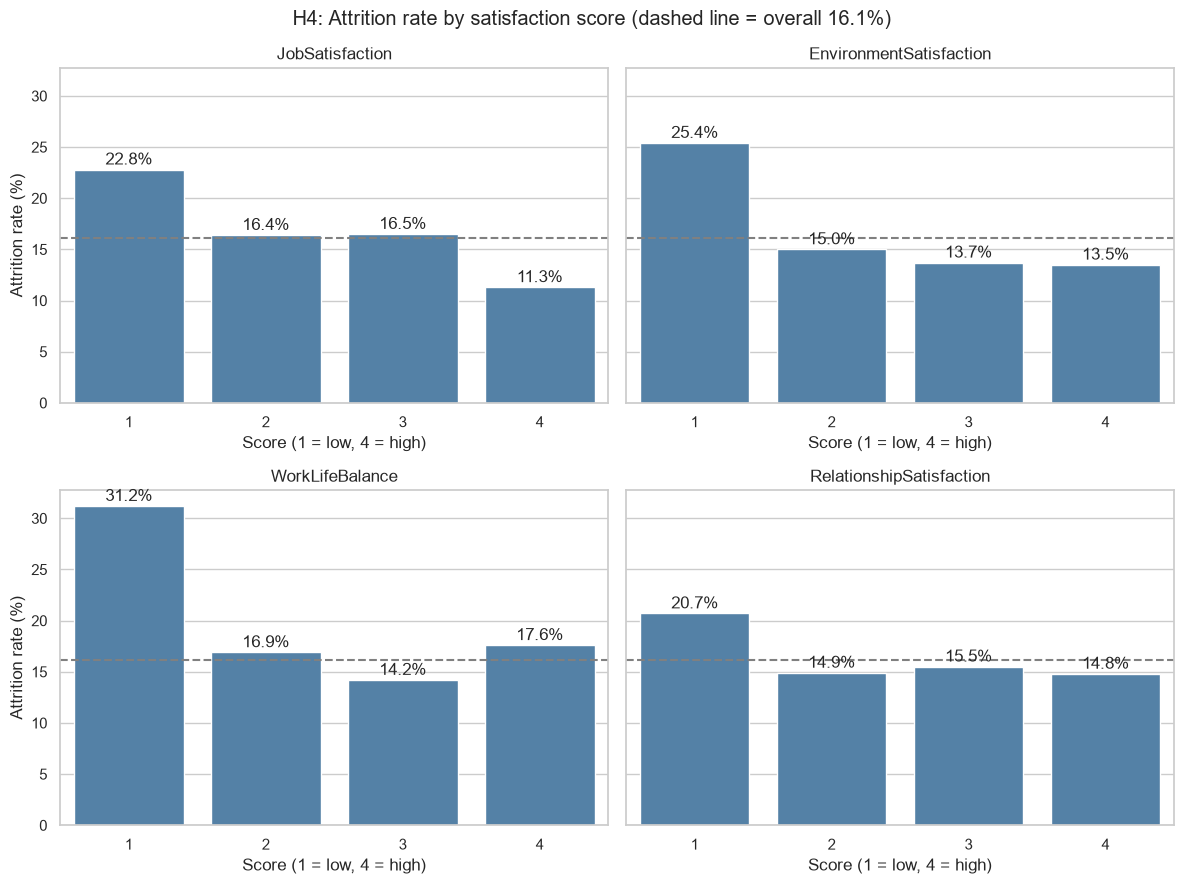

In [28]:
satisfaction_columns = [
    "JobSatisfaction",
    "EnvironmentSatisfaction",
    "WorkLifeBalance",
    "RelationshipSatisfaction"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)

for ax, column in zip(axes.flat, satisfaction_columns):
    rates = attrition_rate(column)["Attrition Rate (%)"]
    sns.barplot(x=rates.index.astype(str), y=rates.values, color="steelblue", ax=ax)
    ax.axhline(overall_rate, ls="--", color="grey")
    ax.set_title(column)
    ax.set_xlabel("Score (1 = low, 4 = high)")
    ax.set_ylabel("Attrition rate (%)")
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")

fig.suptitle("H4: Attrition rate by satisfaction score (dashed line = overall 16.1%)")

plt.tight_layout()

plt.savefig(f"{FIG_DIR}/h4_satisfaction.png", dpi=300, bbox_inches="tight")

plt.show()

In [29]:
for column in satisfaction_columns:
    print(attrition_rate(column)["Attrition Rate (%)"].to_dict())
    chi_square_test(column)
    print()

{1: 22.8, 2: 16.4, 3: 16.5, 4: 11.3}
Chi-square test, JobSatisfaction vs Attrition: chi2 = 17.5, p = 0.00056 -> significant at the 5% level

{1: 25.4, 2: 15.0, 3: 13.7, 4: 13.5}
Chi-square test, EnvironmentSatisfaction vs Attrition: chi2 = 22.5, p = 5.1e-05 -> significant at the 5% level

{1: 31.2, 2: 16.9, 3: 14.2, 4: 17.6}
Chi-square test, WorkLifeBalance vs Attrition: chi2 = 16.3, p = 0.00097 -> significant at the 5% level

{1: 20.7, 2: 14.9, 3: 15.5, 4: 14.8}
Chi-square test, RelationshipSatisfaction vs Attrition: chi2 = 5.2, p = 0.15 -> NOT significant at the 5% level



**Finding (H4): supported.** Low job satisfaction, low environment satisfaction and
poor work-life balance are all linked to leaving (all statistically significant,
p < 0.001). The effect is concentrated at the **lowest score (1)**: attrition is
22.8% at job satisfaction 1, 25.4% at environment satisfaction 1 and **31.2% at
work-life balance 1** (only 80 employees), compared with about 11–18% at scores 2–4.
Relationship satisfaction shows no significant effect (p = 0.15).

**What it means for HR:** the warning sign is a score of 1, not a middling score.
Employees who rate their job, environment or work-life balance at the bottom of the
scale should be followed up quickly, e.g. after each engagement survey.

### 4.6 H5: Business travel

**Hypothesis:** frequent business travel is linked to more leaving.

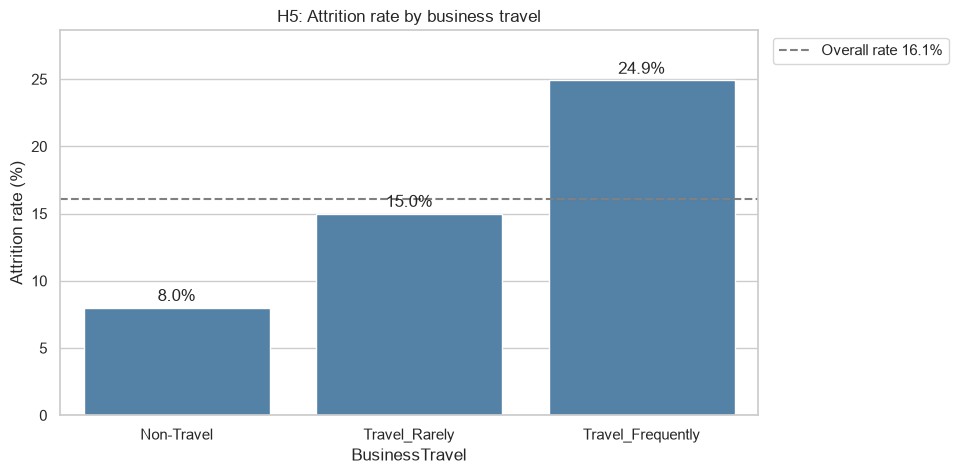

,Employees,Left,Attrition Rate (%)
BusinessTravel,,,
Non-Travel,150,12,8.0
Travel_Rarely,1043,156,15.0
Travel_Frequently,277,69,24.9


In [30]:
plot_attrition_rate(
    "BusinessTravel",
    order=["Non-Travel", "Travel_Rarely", "Travel_Frequently"],
    title="H5: Attrition rate by business travel",
    filename="h5_travel.png"
)

In [31]:
chi_square_test("BusinessTravel");

Chi-square test, BusinessTravel vs Attrition: chi2 = 24.2, p = 5.6e-06 -> significant at the 5% level


**Finding (H5): supported.** Attrition rises with travel: 8.0% for employees who
never travel, 15.0% for those who travel rarely and **24.9% for frequent travellers**,
about 3 times the non-travel rate (statistically significant, p < 0.001). Frequent
travellers are 19% of staff (277 employees).

**What it means for HR:** frequent travel is a workload signal, like overtime (H1).
Spreading travel more evenly, or offering more recovery time to frequent travellers,
is worth considering.

### 4.7 H6: Job role and department

**Hypothesis:** attrition differs strongly by job role (for example Sales Representative).

Department is shown first as context: each department contains several roles.

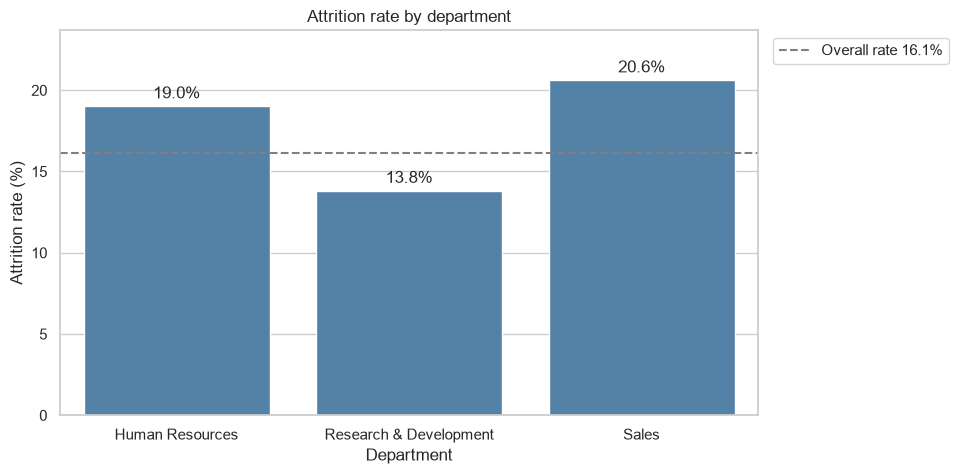

Chi-square test, Department vs Attrition: chi2 = 10.8, p = 0.0045 -> significant at the 5% level


In [32]:
plot_attrition_rate(
    "Department",
    title="Attrition rate by department",
    filename="h6_department.png"
)

chi_square_test("Department");

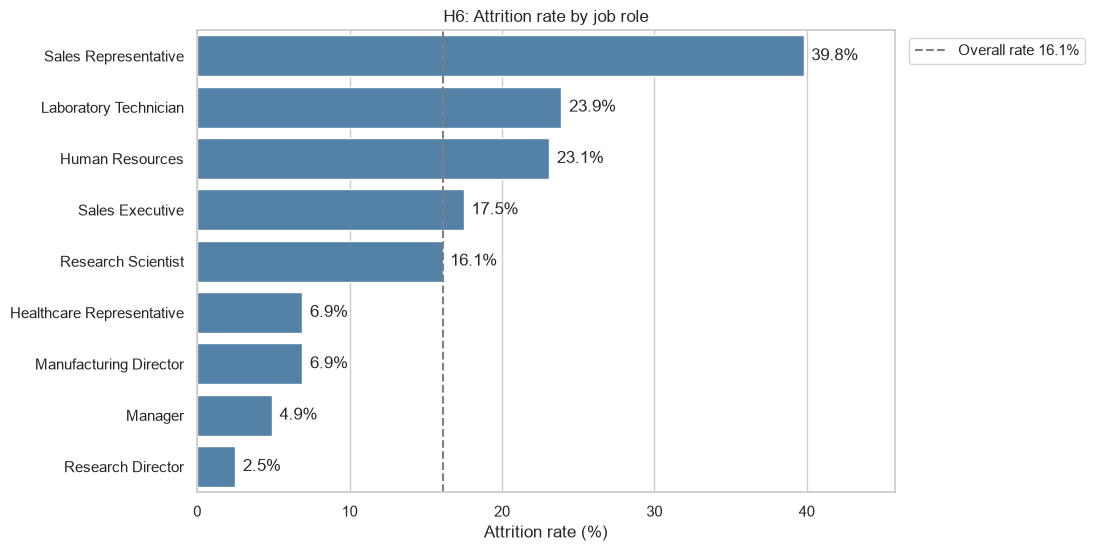

,Employees,Left,Attrition Rate (%)
JobRole,,,
Sales Representative,83,33,39.8
Laboratory Technician,259,62,23.9
Human Resources,52,12,23.1
Sales Executive,326,57,17.5
Research Scientist,292,47,16.1
Healthcare Representative,131,9,6.9
Manufacturing Director,145,10,6.9
Manager,102,5,4.9
Research Director,80,2,2.5


In [33]:
role_order = (
    attrition_rate("JobRole")
    .sort_values("Attrition Rate (%)", ascending=False)
    .index
)

plot_attrition_rate(
    "JobRole",
    order=role_order,
    title="H6: Attrition rate by job role",
    filename="h6_job_role.png",
    horizontal=True
)

In [34]:
chi_square_test("JobRole");

Chi-square test, JobRole vs Attrition: chi2 = 86.2, p = 2.8e-15 -> significant at the 5% level


**Finding (H6): supported.** Attrition differs strongly by role (statistically
significant, p < 0.001): from **39.8% for Sales Representatives** (33 of 83) down to
2.5% for Research Directors, a 16-fold range. Laboratory Technicians (23.9%) and
Human Resources staff (23.1%, only 52 people) are also well above the 16.1% average;
managers, directors and healthcare representatives are all below 7%. Differences
between **departments** are much smaller (Sales 20.6%, HR 19.0%, R&D 13.8%): inside
Sales, Sales Representatives leave at more than twice the rate of Sales Executives
(17.5%), so the role matters more than the department. Overtime is spread similarly
across roles (24–33%), so it does not explain the role differences. Most Sales
Representatives are junior (76 of 83 at job level 1, median tenure 2 years),
which links H6 to H2 and H3.

**What it means for HR:** retention effort should be targeted by role, starting with
Sales Representatives and Laboratory Technicians, the two entry-level roles with the
most leavers.

### 4.8 H7 (control): Gender and education

**Hypothesis:** gender and education make little difference.

This is a *control*: we expect no real effect. Finding no effect is still useful,
because it shows the tests do not flag everything as significant.

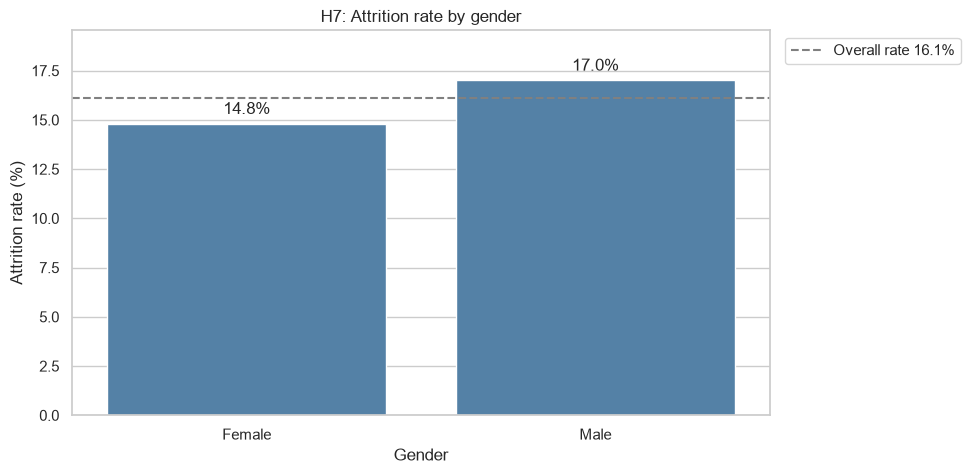

Chi-square test, Gender vs Attrition: chi2 = 1.1, p = 0.29 -> NOT significant at the 5% level


In [35]:
plot_attrition_rate(
    "Gender",
    title="H7: Attrition rate by gender",
    filename="h7_gender.png"
)

chi_square_test("Gender");

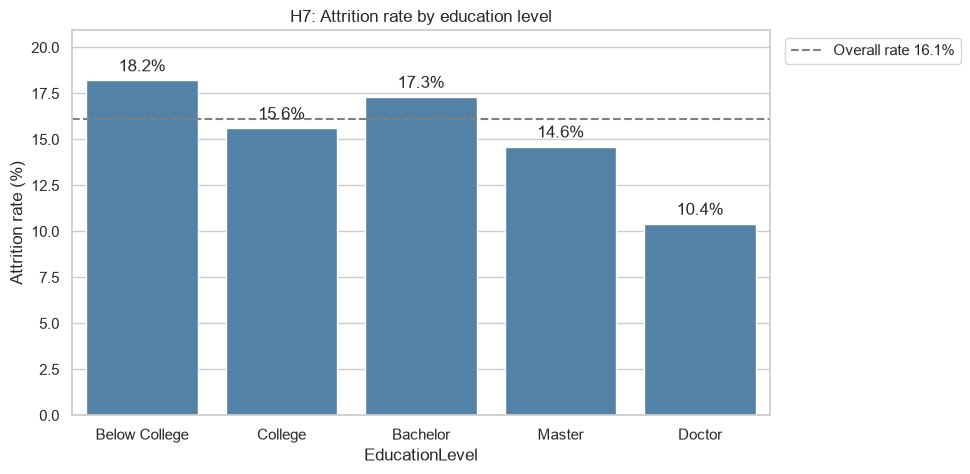

Chi-square test, EducationLevel vs Attrition: chi2 = 3.1, p = 0.55 -> NOT significant at the 5% level


In [36]:
education_labels = {1: "Below College", 2: "College", 3: "Bachelor", 4: "Master", 5: "Doctor"}

eda_df["EducationLevel"] = eda_df["Education"].map(education_labels)

plot_attrition_rate(
    "EducationLevel",
    order=list(education_labels.values()),
    title="H7: Attrition rate by education level",
    filename="h7_education.png"
)

chi_square_test("EducationLevel");

**Finding (H7): supported (no effect, as expected).** Attrition is similar for women
(14.8%) and men (17.0%), and the difference is not statistically significant
(p = 0.29). Across education levels the rate ranges from 10.4% to 18.2%, also not
significant (p = 0.55); the lowest rate (Doctor) is based on only 48 employees.

**What it means for HR:** gender and education are not useful for targeting
retention. This control also shows that our tests do not flag every variable as
significant.

### 4.9 Correlation overview

Correlation measures how strongly two numbers move together (from −1 to +1).
Attrition is converted to 1 (left) / 0 (stayed) to see which numeric columns are most
linked to leaving. This also shows pairs of columns that carry almost the same
information, which matters for the modelling.

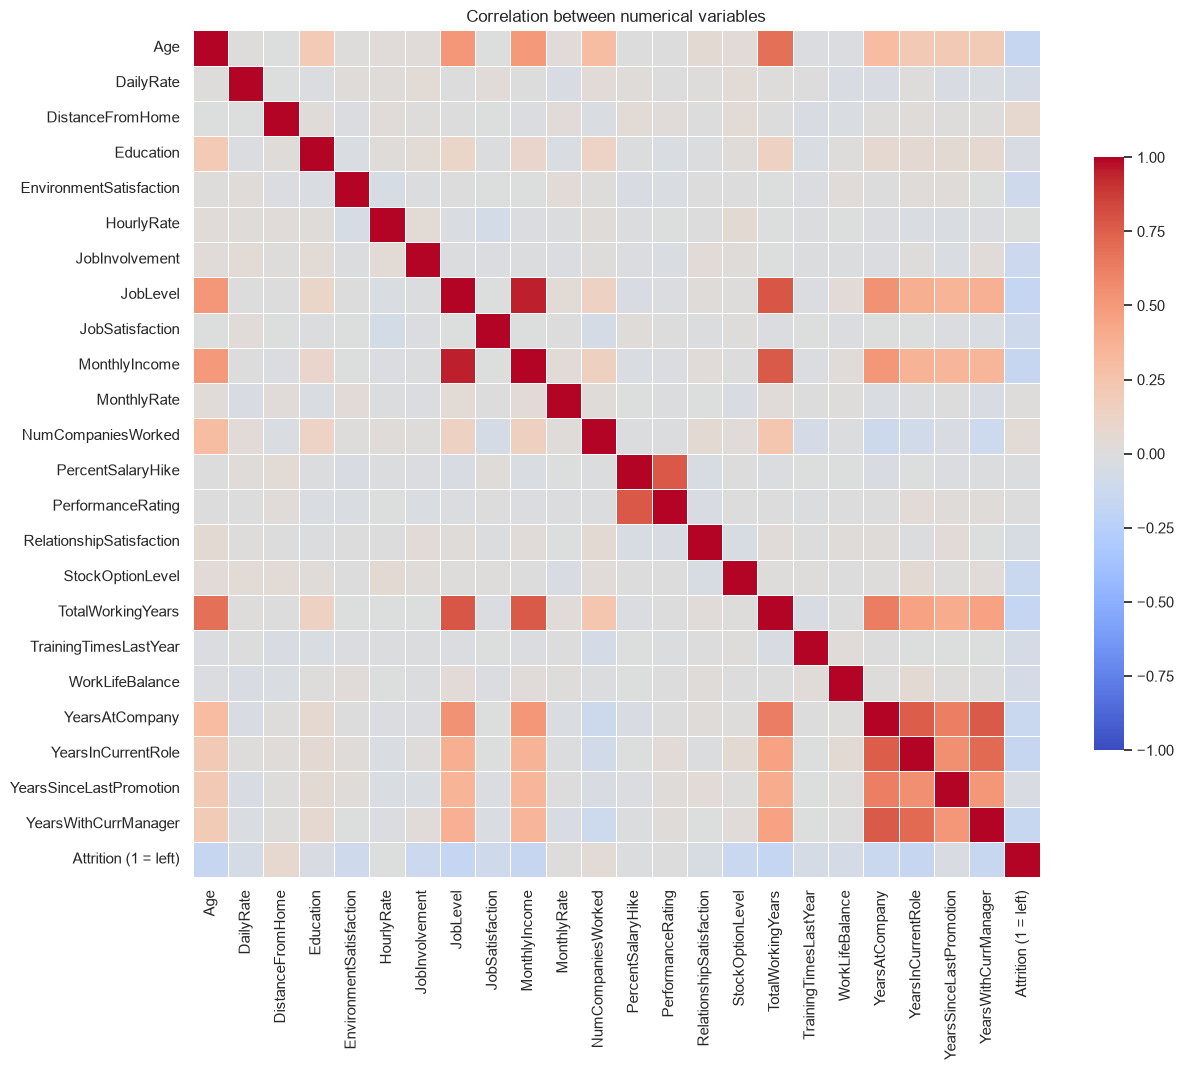

In [37]:
numeric_df = df_clean.select_dtypes(include="number").copy()

numeric_df["Attrition (1 = left)"] = (df_clean["Attrition"] == "Yes").astype(int)

corr = numeric_df.corr()

plt.figure(figsize=(14, 11))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.7}
)

plt.title("Correlation between numerical variables")

plt.savefig(f"{FIG_DIR}/correlation_matrix.png", dpi=300, bbox_inches="tight")

plt.show()

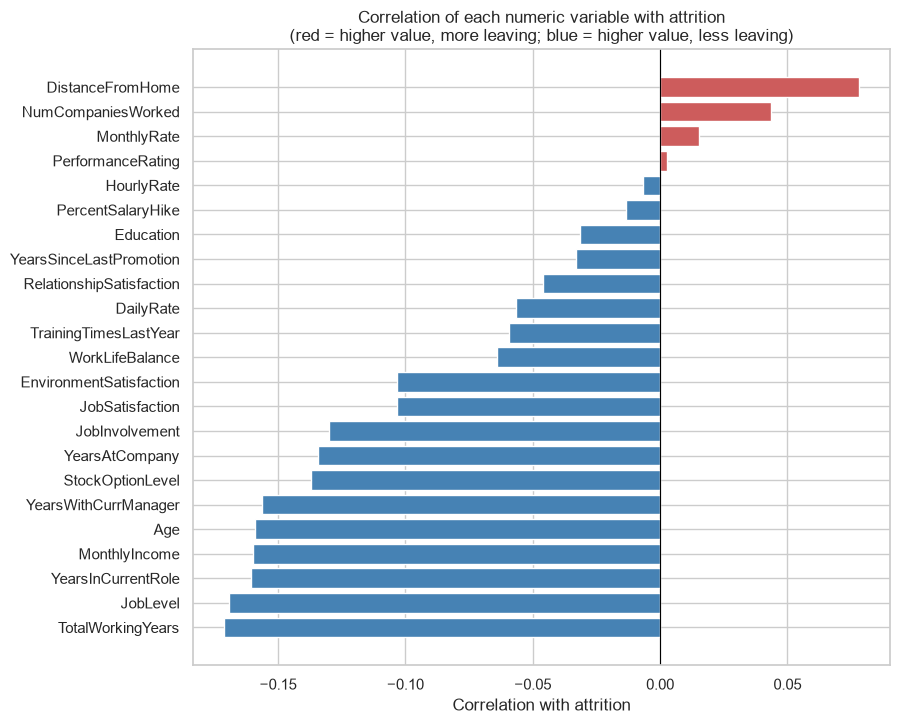

In [38]:
attrition_corr = (
    corr["Attrition (1 = left)"]
    .drop("Attrition (1 = left)")
    .sort_values()
)

plt.figure(figsize=(9, 8))

colors = ["indianred" if v > 0 else "steelblue" for v in attrition_corr.values]

plt.barh(attrition_corr.index, attrition_corr.values, color=colors)

plt.axvline(0, color="black", lw=0.8)

plt.title("Correlation of each numeric variable with attrition\n(red = higher value, more leaving; blue = higher value, less leaving)")

plt.xlabel("Correlation with attrition")

plt.savefig(f"{FIG_DIR}/correlation_with_attrition.png", dpi=300, bbox_inches="tight")

plt.show()

In [39]:
# Pairs of columns that are strongly correlated (|r| > 0.7)

pairs = (
    corr.drop(index="Attrition (1 = left)", columns="Attrition (1 = left)")
    .where(np.triu(np.ones((len(corr) - 1, len(corr) - 1), dtype=bool), k=1))
    .stack()
    .rename("Correlation")
)

pairs[pairs.abs() > 0.7].sort_values(ascending=False).round(2).to_frame()

Correlation
JobLevel           MonthlyIncome                0.95
                   TotalWorkingYears            0.78
PercentSalaryHike  PerformanceRating            0.77
MonthlyIncome      TotalWorkingYears            0.77
YearsAtCompany     YearsWithCurrManager         0.77
                   YearsInCurrentRole           0.76
YearsInCurrentRole YearsWithCurrManager         0.71

**Finding (correlation):** no single numeric variable is strongly linked to attrition
(all correlations are between −0.17 and +0.08). The strongest are all measures of
**seniority and experience**: total working years, job level, years in current role,
monthly income and age (each about −0.16 to −0.17: the more senior, the less likely
to leave). This matches H2 and H3. The three "Rate" columns are close to zero, as
section 3.5 suggested. Correlation only captures straight-line relationships between
numbers, so categorical factors such as overtime (the strongest single factor, H1) and
job role do not appear in this chart.

**For the modelling:** several columns carry almost the same information:
`JobLevel` and `MonthlyIncome` (0.95); `TotalWorkingYears` with both (0.77–0.78);
`YearsAtCompany`, `YearsInCurrentRole` and `YearsWithCurrManager` (0.71–0.77);
`PercentSalaryHike` and `PerformanceRating` (0.77). Logistic Regression is sensitive
to such overlapping inputs (its coefficients become unstable), so consider
regularisation or keeping one column per group; Random Forest is less affected.

### 4.10 Hypothesis scorecard

| # | Hypothesis | Key evidence | Result |
|---|---|---|---|
| H1 | Employees who work overtime leave more | 30.5% vs 10.4%, about 3× (p < 0.001) | **Supported** |
| H2 | Lower monthly income is linked to more leaving | Leavers earn 38% less overall, but the gap mostly disappears within job levels; only at level 1 do leavers earn ~10% less | **Partly supported** |
| H3 | First 2 years / younger staff leave more | 0–2 years: 29.8% vs 8.1% for 11+ years; age 18–25: 35.8% | **Supported** |
| H4 | Low satisfaction / poor work-life balance → more leaving | Score 1: 22.8–31.2% vs ~11–18% at higher scores; relationship satisfaction n.s. | **Supported** |
| H5 | Frequent business travel → more leaving | 24.9% vs 8.0% for non-travel, about 3× | **Supported** |
| H6 | Attrition differs strongly by job role | Sales Representatives 39.8% vs Research Directors 2.5% | **Supported** |
| H7 | Gender and education make little difference (control) | Differences small and not significant (p = 0.29, 0.55) | **Supported** (no effect) |

**The story in three themes** (for the report and slides):

1. **Early-career risk** (H2, H3, H6): junior, new and young employees, often Sales
   Representatives or Laboratory Technicians, leave most. Within this group, the
   lower-paid leave more.
2. **Workload** (H1, H5): overtime and frequent travel each go with about 3 times
   the attrition rate.
3. **Dissatisfaction** (H4): a bottom score on job satisfaction, environment or
   work-life balance is a warning sign.

Gender and education make no difference (H7). These are associations in fictional
data, not proof of cause; the modelling section tests how well these factors
together predict who leaves.